# 02 — Agrupamento de Dados

Este notebook resolve um problema **não supervisionado** em dados de produção agrícola. O objetivo é descobrir grupos de observações semelhantes e avaliar se a estrutura encontrada é estável e interpretável.

## Como ler este notebook

1. Auditar e preparar a base
2. Remover duplicidades e avaliar outliers
3. Codificar categóricas e padronizar escalas
4. Escolher `k` por inércia e Silhouette
5. Comparar K-Means e agrupamento hierárquico
6. Interpretar clusters e confrontá-los com atributos de produção

**Dados:** `data/trabalho3_dados_4.csv`, incluído neste repositório para reprodução do estudo.

> **Padrão de apresentação:** cada etapa combina contexto, execução, visualização e interpretação. Gráficos são usados para responder perguntas específicas, não apenas como decoração.



# Mineração de Dados — Trabalho 3: Agrupamento

O objetivo é **identificar grupos** de observações com características **semelhantes em uma base de produção de arroz em casca** (*paddy*).

Serão utilizados **dois métodos de agrupamento**:

- **K-Means**;
- Agrupamento **Hierárquico** Aglomerativo.



In [ ]:
# Execução portátil: o notebook usa arquivo local em data/
# Não é necessário montar Google Drive.



# **1. Preparação dos dados**

## 1.1 Carregamento e visão geral dos dados

Primeiro, verificamos a **estrutura da base, os tipos dos atributos, valores ausentes, registros duplicados e outliers.**


In [157]:

# ============================================================
# Carregamento e visão geral dos dados
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

#arquivo = 'data/trabalho3_dados_4.csv'
arquivo = 'data/trabalho3_dados_4.csv'
dados = pd.read_csv(arquivo)

ausentes = dados.isnull().sum().sum()
duplicados = dados.duplicated().sum()
perc_duplicados = (duplicados / len(dados)) * 100

print(f"Base {arquivo} carregada com {dados.shape[0]} registros e {dados.shape[1]} atributos.")

# Resumo dos tipos
numericos = dados.select_dtypes(include="number").columns
categoricos = dados.select_dtypes(exclude="number").columns

print("\nRESUMO DOS ATRIBUTOS")
print("-" * 40)
print(f"Atributos numéricos   : {len(numericos)}")
print(f"Atributos categóricos : {len(categoricos)}")
print(f"Total de atributos    : {dados.shape[1]}")

print("\n")
#dados.info()

print(f"\n- Tipos da dados aparentemente Ok!\n- Valores ausentes: {ausentes}"
      f"\n- Registros duplicados: {duplicados} ({perc_duplicados:.2f}%)\n")

# Visualização de algumas duplicidades
duplicados_df = dados[dados.duplicated(keep=False)]
duplicados_df = duplicados_df.sort_values(by=list(dados.columns))

display(duplicados_df.head(9))


Base data/trabalho3_dados_4.csv carregada com 2091 registros e 45 atributos.

RESUMO DOS ATRIBUTOS
----------------------------------------
Atributos numéricos   : 37
Atributos categóricos : 8
Total de atributos    : 45



- Tipos da dados aparentemente Ok!
- Valores ausentes: 0
- Registros duplicados: 260 (12.43%)



,Hectares,Agriblock,Variety,Soil Types,Seedrate(in Kg),LP_Mainfield(in Tonnes),Nursery,Nursery area (Cents),LP_nurseryarea(in Tonnes),DAP_20days,...,Wind Direction_D1_D30,Wind Direction_D31_D60,Wind Direction_D61_D90,Wind Direction_D91_D120,Relative Humidity_D1_D30,Relative Humidity_D31_D60,Relative Humidity_D61_D90,Relative Humidity_D91_D120,Trash(in bundles),Paddy yield(in Kg)
559,1,Chinnasalem,delux ponni,clay,25,12.5,dry,20,1,40,...,E,ENE,NE,NNW,78.6,80,92,88,80,5873
2085,1,Chinnasalem,delux ponni,clay,25,12.5,dry,20,1,40,...,E,ENE,NE,NNW,78.6,80,92,88,80,5873
98,1,Chinnasalem,ponmani,alluvial,25,12.5,wet,20,1,40,...,E,ENE,NE,NNW,78.6,80,92,88,100,5873
959,1,Chinnasalem,ponmani,alluvial,25,12.5,wet,20,1,40,...,E,ENE,NE,NNW,78.6,80,92,88,100,5873
65,1,Cuddalore,delux ponni,clay,25,12.5,dry,20,1,40,...,SW,W,NNW,WSW,72.0,78,88,85,80,5916
1423,1,Cuddalore,delux ponni,clay,25,12.5,dry,20,1,40,...,SW,W,NNW,WSW,72.0,78,88,85,80,5916
245,1,Cuddalore,delux ponni,clay,25,12.5,wet,20,1,40,...,SW,W,NNW,WSW,72.0,78,88,85,80,5836
625,1,Cuddalore,delux ponni,clay,25,12.5,wet,20,1,40,...,SW,W,NNW,WSW,72.0,78,88,85,80,5836
1007,1,Cuddalore,ponmani,clay,25,12.5,dry,20,1,40,...,SW,W,NNW,WSW,72.0,78,88,85,100,5836


### 1.1.1 Distribuição da produtividade antes do agrupamento

Antes de retirar os atributos de resultado da formação dos clusters, observamos sua distribuição apenas para **compreender o contexto da base**. A produtividade não participa do K-Means nem do agrupamento hierárquico; ela será usada depois para interpretar os grupos encontrados.


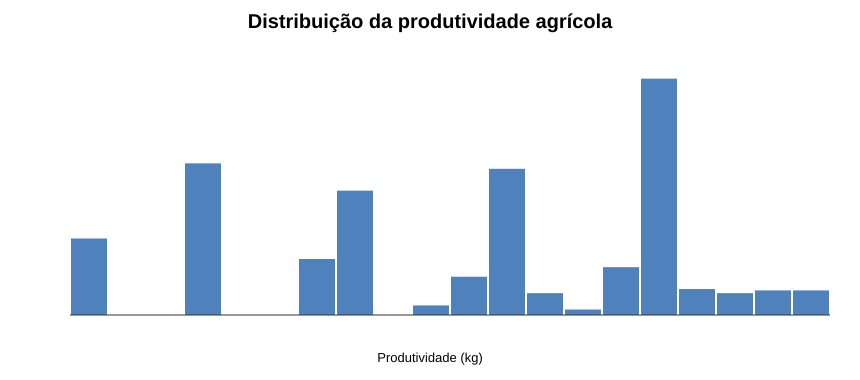

In [ ]:
plt.figure(figsize=(9,4))
plt.hist(dados['Paddy yield(in Kg)'], bins=20, edgecolor='black')
plt.title('Distribuição da produtividade agrícola')
plt.xlabel('Paddy yield (kg)')
plt.ylabel('Frequência')
plt.show()


**Interpretação:** o histograma mostra a amplitude e a concentração da produtividade antes da clusterização. Como `Paddy yield(in Kg)` é um resultado que queremos comparar **depois** da formação dos grupos, ele é excluído das features usadas para definir os clusters, evitando circularidade na interpretação.


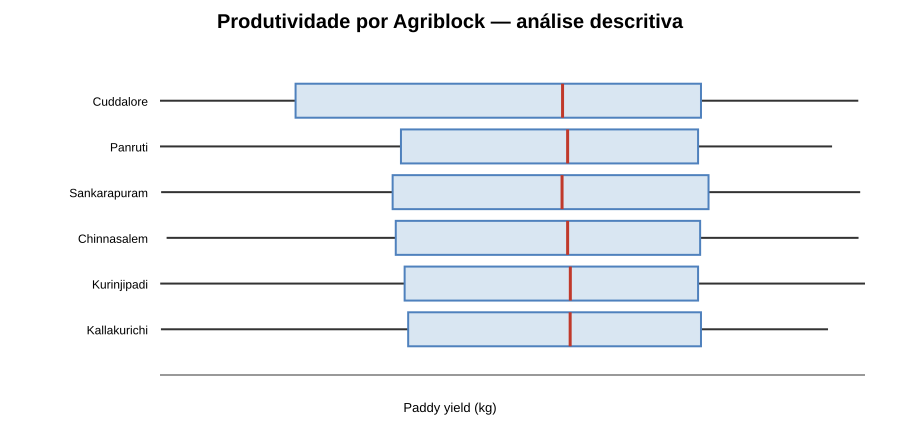

In [ ]:
plt.figure(figsize=(10,5))
dados.boxplot(column='Paddy yield(in Kg)', by='Agriblock', rot=25)
plt.title('Produtividade por Agriblock — análise descritiva')
plt.suptitle('')
plt.ylabel('Paddy yield (kg)')
plt.show()


**Leitura:** os boxplots revelam diferenças de nível e dispersão entre Agriblocks. Essa visualização não é usada para definir `k`; ela funciona como referência descritiva para verificar, ao final, se os clusters encontrados refletem estruturas regionais já existentes na base.



## 1.2. Limpeza básica - Exclusão dos registros duplicados

Foram **removidos os registros exatamente duplicados** para evitar que observações repetidas tenham peso excessivo no processo de agrupamento.


In [130]:
# ============================================================
# Remoção das duplicidades
# ============================================================

dados = dados.drop_duplicates().reset_index(drop=True)

print(f"Base após remoção das duplicidades: {dados.shape[0]} registros.")


Base após remoção das duplicidades: 1831 registros.


## 1.3 Verificação de outliers

In [155]:
# ============================================================
# Verificação de possíveis outliers pelo método IQR
# ============================================================

numericos = dados.select_dtypes(include="number").columns

print("VERIFICAÇÃO DE POSSÍVEIS OUTLIERS - MÉTODO IQR")
print("-" * 65)

for atributo in numericos:

    Q1 = dados[atributo].quantile(0.25)
    Q3 = dados[atributo].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    mascara_outlier = (
        (dados[atributo] < limite_inferior) |
        (dados[atributo] > limite_superior)
    )

    quantidade = mascara_outlier.sum()

    if quantidade > 0:
        percentual = quantidade / len(dados) * 100

        print(f"\nAtributo: {atributo}")
        print(f"Possíveis outliers: {quantidade} ({percentual:.1f}% da base)")

print("\n" + "-" * 65)
print("CONCLUSÃO")

print(
    "O método IQR sinalizou 290 registros da variável "
    "'Inst Wind Speed_D61_D90(in Knots)' com valor de 4 nós."
)

print(
    "A variável apresenta apenas os valores 4, 8 e 10 nós, "
    "e o valor 4 ocorre em aproximadamente 15,8% dos registros, "
    "indicando um valor recorrente na base e não uma ocorrência isolada."
)

print(
    "Por esse motivo, os registros serão mantidos, pois sua remoção "
    "poderia eliminar uma característica real dos dados e influenciar "
    "artificialmente o processo de agrupamento."
)

VERIFICAÇÃO DE POSSÍVEIS OUTLIERS - MÉTODO IQR
-----------------------------------------------------------------

Atributo: Inst Wind Speed_D61_D90(in Knots)
Possíveis outliers: 290 (15.8% da base)

-----------------------------------------------------------------
CONCLUSÃO
O método IQR sinalizou 290 registros da variável 'Inst Wind Speed_D61_D90(in Knots)' com valor de 4 nós.
A variável apresenta apenas os valores 4, 8 e 10 nós, e o valor 4 ocorre em aproximadamente 15,8% dos registros, indicando um valor recorrente na base e não uma ocorrência isolada.
Por esse motivo, os registros serão mantidos, pois sua remoção poderia eliminar uma característica real dos dados e influenciar artificialmente o processo de agrupamento.



## 1.4 Separação dos atributos de resultado (Trash e Paddy yield)

Os atributos **`Trash(in bundles)/Descarte` e `Paddy yield(in Kg)/Produtividade` foram retirados da base** usada porque são justamente os resultados que queremos analisar depois e comparar os clusters encontrados.


In [132]:
# ============================================================
# Separação dos atributos de resultado
# ============================================================

atributos_resultado = [
    'Trash(in bundles)',
    'Paddy yield(in Kg)'
]

resultados = dados[atributos_resultado].copy()
X = dados.drop(columns=atributos_resultado).copy()

print(f"Registros para agrupamento : {X.shape[0]}")
print(f"Atributos para agrupamento : {X.shape[1]}")
print(f"Atributos reservados       : {len(atributos_resultado)}")


Registros para agrupamento : 1831
Atributos para agrupamento : 43
Atributos reservados       : 2



## 1.5 Tratamento dos atributos categóricos

Os atributos categóricos precisam ser representados numericamente.

**Avaliar quantidade de categorias** existentes em cada atributo e o **impacto do uso do one hot encoding.**


In [133]:

# ============================================================
# Verificação dos atributos categóricos
# ============================================================

categoricos_X = X.select_dtypes(exclude="number").columns

print("ATRIBUTOS CATEGÓRICOS")
print("-" * 50)

total_categorias = 0

for atributo in categoricos_X:
    quantidade = X[atributo].nunique()
    total_categorias += quantidade
    print(f"{atributo}: {quantidade} categorias")

print("-" * 50)
print(f"Total de categorias: {total_categorias} em {len(categoricos)} atributos")


ATRIBUTOS CATEGÓRICOS
--------------------------------------------------
Agriblock: 6 categorias
Variety: 3 categorias
Soil Types: 2 categorias
Nursery: 2 categorias
Wind Direction_D1_D30: 6 categorias
Wind Direction_D31_D60: 5 categorias
Wind Direction_D61_D90: 5 categorias
Wind Direction_D91_D120: 6 categorias
--------------------------------------------------
Total de categorias: 35 em 8 atributos



Como os atributos possuem poucas categorias e não apresentam uma relação de ordem entre elas, **One-Hot Encoding** foi aplicado e **35 novos atributos serão criados**.

**Observação:** Como algumas variáveis possuem mais categorias, elas geram mais colunas após o One-Hot Encoding e podem ter maior peso na formação dos grupos.


In [134]:
# ============================================================
# One-Hot Encoding
# ============================================================

X_encoded = pd.get_dummies(
    X,
    columns=categoricos_X,
    dtype=int
)

print(f"Atributos antes da conversão : {X.shape[1]}")
print(f"Atributos criados pelo One-Hot: {len(X_encoded.columns) - len(X.select_dtypes(include='number').columns)}")
print(f"Atributos após a conversão   : {X_encoded.shape[1]}")

Atributos antes da conversão : 43
Atributos criados pelo One-Hot: 35
Atributos após a conversão   : 70



## 1.6 Padronização dos atributos

Como os dados possuem **escalas diferentes** — por exemplo, temperatura, chuva, hectares e quantidade de insumos — foi aplicado o `StandardScaler`.

Assim, os atributos passam a contribuir de forma **mais comparável** para as medidas de distância.


In [135]:
# ============================================================
# Padronização
# ============================================================

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_padronizado = pd.DataFrame(
    scaler.fit_transform(X_encoded),
    columns=X_encoded.columns,
    index=X_encoded.index
)

print(
    f"Base preparada para agrupamento: "
    f"{X_padronizado.shape[0]} registros e "
    f"{X_padronizado.shape[1]} atributos."
)

#display(X_padronizado.head(3))


Base preparada para agrupamento: 1831 registros e 70 atributos.


# **2. Formar e validar grupos**

## 2.1 Primeiro método: K-Means

O K-Means divide os dados em `k` grupos, buscando manter os elementos de um mesmo grupo próximos entre si.

Para escolher uma quantidade adequada de grupos, foram testados valores de **2 a 10**, utilizando:

- **Método do Cotovelo**, baseado na inércia;
- **Coeficiente de Silhueta**, que avalia coesão e separação dos grupos.


K   Inércia       Silhueta
--------------------------------
2   100401.58     0.2403
3   79904.67      0.3103
4   63384.40      0.3804
5   47929.47      0.4563
6   32904.72      0.5249
7   29812.81      0.4816
8   27196.29      0.4543
9   24637.19      0.4401
10  22124.67      0.4243


inercia / Cotovelo: mede a proximidade dos registros ao centro do seu grupo. Menor é melhor.
silhueta: mede a proximidade dentro do grupo e a separação dos outros grupos. Maior é melhor.




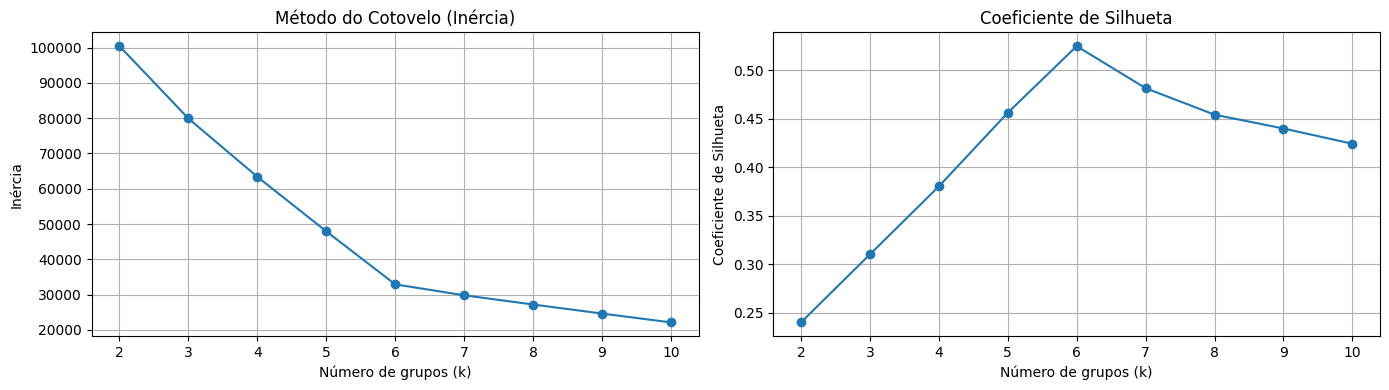

In [136]:
# ============================================================
# K-Means - análise da quantidade de grupos
# ============================================================

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inercias = []  # mede o quanto os registros estão distantes do centro do grupo (centroide) ao qual pertencem.
silhuetas = [] # mede o quanto os registros estão próximos do seu grupo e distantes dos outros grupos.
valores_k = range(2, 11) # 2 a 10 grupos

for k in valores_k:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10 # executa o K-Means 10 vezes com centroides iniciais diferentes e mantém o melhor resultado
    )

    grupos = kmeans.fit_predict(X_padronizado)

    inercias.append(kmeans.inertia_)
    silhuetas.append(
        silhouette_score(X_padronizado, grupos)
    )

print("K   Inércia       Silhueta")
print("-" * 32)

for k, inercia, silhueta in zip(valores_k, inercias, silhuetas):
    print(f"{k:<3} {inercia:<13.2f} {silhueta:.4f}")

print("\n")
print("inercia / Cotovelo: mede a proximidade dos registros ao centro do seu grupo. Menor é melhor.")
print("silhueta: mede a proximidade dentro do grupo e a separação dos outros grupos. Maior é melhor.")
print("\n")


# ============================================================
# Gráficos Cotovelo (Elbow) e Coeficiente de Silhueta
# ============================================================

fig, ax = plt.subplots(1, 2, figsize=(14, 4))

ax[0].plot(valores_k, inercias, marker='o')
ax[0].set_xlabel("Número de grupos (k)")
ax[0].set_ylabel("Inércia")
ax[0].set_title("Método do Cotovelo (Inércia)")
ax[0].set_xticks(list(valores_k))
ax[0].grid()

ax[1].plot(valores_k, silhuetas, marker='o')
ax[1].set_xlabel("Número de grupos (k)")
ax[1].set_ylabel("Coeficiente de Silhueta")
ax[1].set_title("Coeficiente de Silhueta")
ax[1].set_xticks(list(valores_k))
ax[1].grid()

plt.tight_layout()
plt.show()



### Escolha de `k`

Os resultados apontaram **6 grupos** como a melhor solução:

- maior coeficiente de silhueta: **0,5249**;
- redução acentuada da inércia até aproximadamente `k = 6`;
- após esse ponto, os ganhos passam a ser menores.

Assim, foi adotado **`k = 6`**.


In [145]:
# ============================================================
# K-Means com 6 grupos
# ============================================================

kmeans = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=10
)

clusters_kmeans = kmeans.fit_predict(X_padronizado)

dados_kmeans = dados.copy()
dados_kmeans["Cluster_KMeans"] = clusters_kmeans

quantidade_grupos = (
    dados_kmeans["Cluster_KMeans"]
    .value_counts()
    .sort_index()
)

print("QUANTIDADE DE REGISTROS POR GRUPO")
print("-" * 40)

for grupo, quantidade in quantidade_grupos.items():
    print(f"Grupo {grupo}: {quantidade} registros")

print("\nOs 1.831 registros foram distribuídos entre seis grupos com tamanhos relativamente equilibrados, sem a formação de clusters muito pequenos.")

QUANTIDADE DE REGISTROS POR GRUPO
----------------------------------------
Grupo 0: 311 registros
Grupo 1: 391 registros
Grupo 2: 278 registros
Grupo 3: 278 registros
Grupo 4: 290 registros
Grupo 5: 283 registros

Os 1.831 registros foram distribuídos entre seis grupos com tamanhos relativamente equilibrados, sem a formação de clusters muito pequenos.



## 2.2. Segundo método: Agrupamento Hierárquico

Como segundo método, foi utilizado o **Agrupamento Hierárquico Aglomerativo**.

**Foram testadas três formas de ligação** (linkage):

- `**ward**`: une os grupos que provocam o menor aumento da variabilidade interna. Tende a produzir grupos mais compactos e equilibrados.
- `**complete**`: considera a distância entre os dois registros mais distantes dos grupos. Favorece grupos mais compactos e evita juntar grupos que tenham pontos muito afastados.;
- `**average**`: considera a média das distâncias entre todos os pares de registros dos dois grupos. É uma solução intermediária..

Também foram avaliadas soluções de **2 a 10 grupos**, utilizando novamente o coeficiente de silhueta.


COMPARAÇÃO DOS LINKAGES
-------------------------------------------------------
K    Ward           Complete       Average        
-------------------------------------------------------
2    0.2424         0.2403         0.2424         
3    0.3103         0.3186         0.3186         
4    0.3804         0.3694         0.3694         
5    0.4563         0.4380         0.4380         
6    0.5249         0.5249         0.5249         
7    0.4685         0.4861         0.4928         
8    0.4488         0.4546         0.4582         
9    0.4316         0.4217         0.4395         
10   0.3922         0.3822         0.4158         




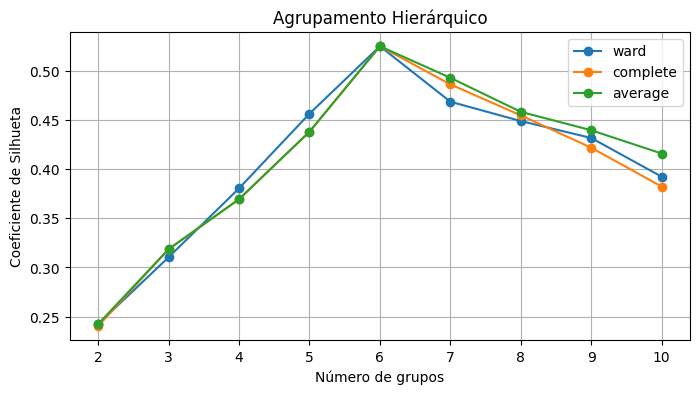



Os três critérios de ligação apresentam a maior Silhueta com 6 grupos (≈ 0.5249), indicando k = 6 como a melhor configuração.
Como houve empate em k = 6, Ward foi escolhido por que mantém os elementos mais semelhantes dentro de cada grupo.


In [146]:
# ============================================================
# Agrupamento Hierárquico - análise dos parâmetros
# ============================================================

from sklearn.cluster import AgglomerativeClustering

linkages = [
    "ward",      # menor aumento da variabilidade dentro dos grupos
    "complete",  # distância entre os pontos mais distantes dos grupos
    "average"    # média das distâncias entre os pontos dos grupos
]
valores_k = range(2, 11)  # 2 a 10 grupos

resultados_hierarquico = []

for linkage in linkages:
    for k in valores_k:

        modelo = AgglomerativeClustering(
            n_clusters=k,
            linkage=linkage
        )

        grupos = modelo.fit_predict(X_padronizado)

        silhueta = silhouette_score(
            X_padronizado,
            grupos
        )

        resultados_hierarquico.append([
            linkage,
            k,
            silhueta
        ])

resultado_h = pd.DataFrame(
    resultados_hierarquico,
    columns=["Linkage", "Grupos", "Silhueta"]
)

# print(resultado_h.to_string(index=False))

# print("\nMELHOR RESULTADO POR LINKAGE")
# print("-" * 45)

# melhores = resultado_h.loc[
#     resultado_h.groupby("Linkage")["Silhueta"].idxmax()
# ]

# ============================================================
# Comparação dos linkages
# ============================================================

print("COMPARAÇÃO DOS LINKAGES")
print("-" * 55)
print(f"{'K':<5}{'Ward':<15}{'Complete':<15}{'Average':<15}")
print("-" * 55)

for k in valores_k:

    ward = resultado_h[
        (resultado_h["Linkage"] == "ward") &
        (resultado_h["Grupos"] == k)
    ]["Silhueta"].values[0]

    complete = resultado_h[
        (resultado_h["Linkage"] == "complete") &
        (resultado_h["Grupos"] == k)
    ]["Silhueta"].values[0]

    average = resultado_h[
        (resultado_h["Linkage"] == "average") &
        (resultado_h["Grupos"] == k)
    ]["Silhueta"].values[0]

    linha = f"{k:<5}{ward:<15.4f}{complete:<15.4f}{average:<15.4f}"

    if k == 6:
        print(f"\033[1m{linha}\033[0m")  # negrito
    else:
        print(linha)

print("\n")
# ============================================================
# Comparação dos linkages
# ============================================================

plt.figure(figsize=(8, 4))

for linkage in linkages:
    dados_linkage = resultado_h[
        resultado_h["Linkage"] == linkage
    ]

    plt.plot(
        dados_linkage["Grupos"],
        dados_linkage["Silhueta"],
        marker="o",
        label=linkage
    )

plt.xlabel("Número de grupos")
plt.ylabel("Coeficiente de Silhueta")
plt.title("Agrupamento Hierárquico")
plt.xticks(list(valores_k))
plt.legend()
plt.grid()
plt.show()

print("\n")
print("Os três critérios de ligação apresentam a maior Silhueta com 6 grupos (≈ 0.5249), indicando k = 6 como a melhor configuração.")
print("Como houve empate em k = 6, Ward foi escolhido por que mantém os elementos mais semelhantes dentro de cada grupo.")


## Criação do agrupamento


In [148]:
# ============================================================
# Agrupamento Hierárquico com 6 grupos - Ward
# ============================================================

hierarquico = AgglomerativeClustering(
    n_clusters=6,
    linkage="ward"
)

clusters_hierarquico = hierarquico.fit_predict(X_padronizado)

dados_hierarquico = dados.copy()
dados_hierarquico["Cluster_Hierarquico"] = clusters_hierarquico

quantidade_grupos_h = (
    dados_hierarquico["Cluster_Hierarquico"]
    .value_counts()
    .sort_index()
)

print("QUANTIDADE DE REGISTROS POR GRUPO")
print("-" * 40)

for grupo, quantidade in quantidade_grupos_h.items():
    print(f"Grupo {grupo}: {quantidade} registros")


print("\nA distribuição também é compatível com a obtida pelo K-Means, reforçando a semelhança entre as duas soluções.")

QUANTIDADE DE REGISTROS POR GRUPO
----------------------------------------
Grupo 0: 391 registros
Grupo 1: 278 registros
Grupo 2: 311 registros
Grupo 3: 290 registros
Grupo 4: 283 registros
Grupo 5: 278 registros

A distribuição também é compatível com a obtida pelo K-Means, reforçando a semelhança entre as duas soluções.



## **3. Comparação dos dois métodos**

Os **grupos** obtidos pelos dois métodos **apresentaram as mesmas quantidades de registros**.

Para confirmar se a composição também era a mesma, foi utilizado o **Índice Rand Ajustado (ARI)**.

Um valor igual a **1** indica agrupamentos idênticos, mesmo que os números atribuídos aos grupos sejam diferentes.


In [140]:
# ============================================================
# Comparação entre K-Means e Hierárquico
# ============================================================

from sklearn.metrics import adjusted_rand_score

ari = adjusted_rand_score(
    clusters_kmeans,
    clusters_hierarquico
)

print(f"Índice Rand Ajustado (ARI): {ari:.4f}\n")

# Correspondência intuitiva entre os grupos
mapeamento = []

for grupo_k in sorted(set(clusters_kmeans)):

    filtro = clusters_kmeans == grupo_k

    grupo_h = (
        pd.Series(clusters_hierarquico[filtro])
        .mode()[0]
    )

    quantidade = filtro.sum()

    mapeamento.append([
        grupo_k,
        grupo_h,
        quantidade
    ])

comparacao_grupos = pd.DataFrame(
    mapeamento,
    columns=[
        "Grupo K-Means",
        "Grupo Hierárquico",
        "Registros"
    ]
)

display(comparacao_grupos)


Índice Rand Ajustado (ARI): 1.0000



,Grupo K-Means,Grupo Hierárquico,Registros
0,0,2,311
1,1,0,391
2,2,1,278
3,3,5,278
4,4,3,290
5,5,4,283



O resultado **ARI = 1,0000** mostra que K-Means e Hierárquico encontraram **exatamente os mesmos grupos**.

A diferença ocorre apenas na numeração atribuída a cada cluster.

**Como os resultados são equivalentes**, a partir deste ponto os grupos do **K-Means** serão utilizados apenas como referência, simplificando as análises seguintes e evitando repetições.



## **4. Análise da produção e do descarte por grupo** (associado ao K-Means)

Agora os atributos `Paddy yield(in Kg)` e `Trash(in bundles)` são **reincorporados**.

O objetivo é **verificar como os grupos encontrados se comportam em relação à produção e ao descarte**.


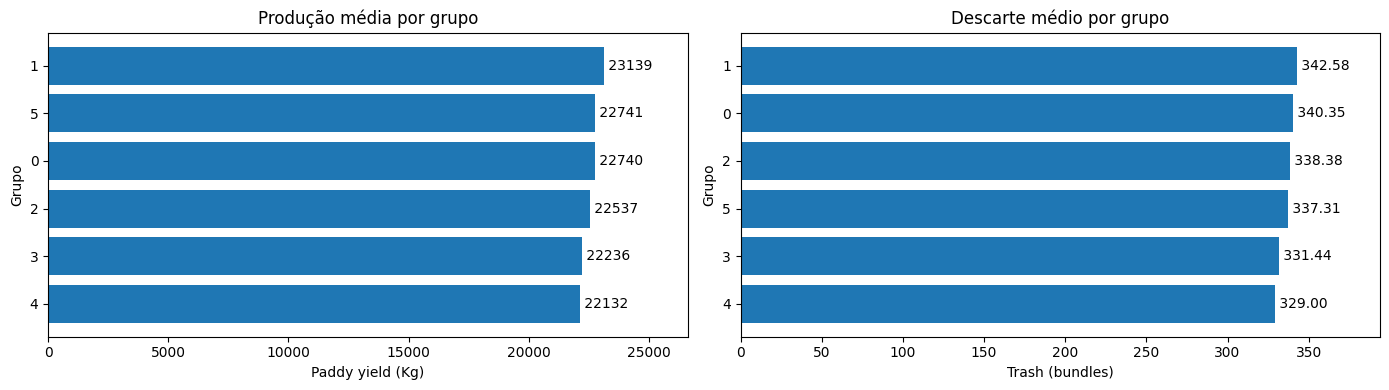



Correlação entre produção e descarte (médias dos grupos) : 0.94
Correlação entre produção e descarte (registro a registro): 0.96


In [141]:
# ============================================================
# Produção e descarte por grupo
# ============================================================

resumo_resultados = (
    dados_kmeans
    .groupby("Cluster_KMeans")
    .agg(
        Registros=("Cluster_KMeans", "size"),
        Paddy_Medio=("Paddy yield(in Kg)", "mean"),
        Paddy_Mediana=("Paddy yield(in Kg)", "median"),
        Trash_Medio=("Trash(in bundles)", "mean"),
        Trash_Mediana=("Trash(in bundles)", "median")
    )
    .round(2)
)

resumo_resultados.index.name = "Grupo"

#display(resumo_resultados)
print("\n")

# ============================================================
# Visualização: produção e descarte
# ============================================================

fig, ax = plt.subplots(1, 2, figsize=(14, 4))

# Produção média
producao = resumo_resultados.sort_values("Paddy_Medio")

barras0 = ax[0].barh(
    producao.index.astype(str),
    producao["Paddy_Medio"]
)

ax[0].set_title("Produção média por grupo")
ax[0].set_xlabel("Paddy yield (Kg)")
ax[0].set_ylabel("Grupo")
ax[0].set_xlim(0, producao["Paddy_Medio"].max() * 1.15)

for barra, valor in zip(barras0, producao["Paddy_Medio"]):
    ax[0].text(
        valor,
        barra.get_y() + barra.get_height()/2,
        f" {valor:.0f}",
        va="center"
    )

# Descarte médio
descarte = resumo_resultados.sort_values("Trash_Medio")

barras1 = ax[1].barh(
    descarte.index.astype(str),
    descarte["Trash_Medio"]
)

ax[1].set_title("Descarte médio por grupo")
ax[1].set_xlabel("Trash (bundles)")
ax[1].set_ylabel("Grupo")
ax[1].set_xlim(0, descarte["Trash_Medio"].max() * 1.15)

for barra, valor in zip(barras1, descarte["Trash_Medio"]):
    ax[1].text(
        valor,
        barra.get_y() + barra.get_height()/2,
        f" {valor:.2f}",
        va="center"
    )

plt.tight_layout()
plt.show()

# ============================================================
# Correlação entre produção e descarte
# ============================================================

# Correlação ao nível de grupo (médias dos 6 grupos)
correlacao_grupos = resumo_resultados["Paddy_Medio"].corr(
    resumo_resultados["Trash_Medio"]
)

# Correlação ao nível de registro (todos os 2.091 registros, sem agregar por grupo)
correlacao_registros = dados_kmeans["Paddy yield(in Kg)"].corr(
    dados_kmeans["Trash(in bundles)"]
)

print("\n")
print(f"Correlação entre produção e descarte (médias dos grupos) : {correlacao_grupos:.2f}")
print(f"Correlação entre produção e descarte (registro a registro): {correlacao_registros:.2f}")



Os resultados mostram diferenças moderadas entre os grupos:

- **Grupo 1**: maior produção média **e** também o maior descarte médio;
- **Grupo 4**: menor produção média **e** também o menor descarte médio;
- Produção e descarte crescem juntos (correlação de 0,94 a 0,96) — **mais produção geralmente significa mais material descartado**, não menos.






## **5 - Análise descritiva dos grupos**

## 5.1 - Caracterização dos grupos

Para entender o que diferencia os agrupamentos, foram analisados:

1. os **atributos numéricos com maior diferença entre os grupos**;
2. as **categorias predominantes** em cada grupo.




In [154]:
# ============================================================
# Atributos numéricos que mais diferenciam os grupos
# ============================================================

numericos_X = X.select_dtypes(include="number").columns

perfil_padronizado = X_padronizado[numericos_X].copy()
perfil_padronizado["Grupo"] = clusters_kmeans

medias_padronizadas = perfil_padronizado.groupby("Grupo").mean()

variacao = (
    medias_padronizadas.max() -
    medias_padronizadas.min()
).sort_values(ascending=False)

top_atributos = variacao.head(10).index

print("TOP 10 ATRIBUTOS NUMÉRICOS QUE MAIS DIFERENCIAM OS GRUPOS")
print("-" * 60)

perfil_numerico = (
    dados_kmeans
    .groupby("Cluster_KMeans")[top_atributos]
    .mean()
    .round(2)
)

perfil_numerico.index.name = "Grupo"

tabela = perfil_numerico.T

# ============================================================
# Destaque dos valores extremos por atributo
# ============================================================

# 3 atributos com maior variação entre os grupos (já ordenados em 'variacao')
linhas_destaque = top_atributos[:10]

def destacar_extremos(linha):
    estilos = [''] * len(linha)
    if linha.name in linhas_destaque:
        idx_max = linha.values.argmax()
        idx_min = linha.values.argmin()
        estilos[idx_max] = 'font-weight: bold; color: #b22222'  # maior valor
        estilos[idx_min] = 'font-weight: bold; color: #1f77b4'  # menor valor
    return estilos

display(
    tabela.style
    .format("{:.1f}")
    .apply(destacar_extremos, axis=1)
)

print("\nEntre os atributos numéricos, o padrão principal é climático: temperatura, umidade e velocidade do vento.")
print("\nEx.: Na umidade relativa entre os dias 61 e 90, o Grupo 2 teve a menor média (81%) e o Grupo 5 a maior (92%), diferença de 11 pontos")

TOP 10 ATRIBUTOS NUMÉRICOS QUE MAIS DIFERENCIAM OS GRUPOS
------------------------------------------------------------


Grupo,0,1,2,3,4,5
Min temp_D91_D120,16.0,16.5,15.5,16.0,18.0,15.0
Relative Humidity_D61_D90,84.0,83.0,81.0,88.0,84.0,92.0
Max temp_D91_D120,30.5,35.0,32.5,33.0,33.0,31.5
Max temp_D1_D30,34.0,32.0,33.0,34.0,35.0,31.0
Relative Humidity_D1_D30,64.6,72.7,88.5,72.0,85.0,78.6
Inst Wind Speed_D61_D90(in Knots),10.0,10.0,8.0,8.0,4.0,8.0
Min temp_D31_D60,18.5,17.5,17.0,16.0,18.0,15.5
Min temp_D1_D30,19.5,20.5,19.0,18.5,20.0,18.0
Relative Humidity_D91_D120,87.0,81.0,84.0,85.0,79.0,88.0
Max temp_D61_D90,32.5,34.0,31.5,31.0,33.5,33.0



Entre os atributos numéricos, o padrão principal é climático: temperatura, umidade e velocidade do vento.

Ex.: Na umidade relativa entre os dias 61 e 90, o Grupo 2 teve a menor média (81%) e o Grupo 5 a maior (92%), diferença de 11 pontos


In [153]:
# ============================================================
# Perfil dos grupos: categorias predominantes + produção/descarte
# ============================================================

categorias_resumo = {
    "Variety": "Variety",
    "Soil Types": "Soil",
    "Nursery": "Nursery",
    "Wind Direction_D1_D30": "Wind D1-D30",
    "Wind Direction_D31_D60": "Wind D31-D60",
    "Wind Direction_D61_D90": "Wind D61-D90",
    "Wind Direction_D91_D120": "Wind D91-D120"
}

resumo_categorias = []

for grupo in sorted(dados_kmeans["Cluster_KMeans"].unique()):

    dados_grupo = dados_kmeans[dados_kmeans["Cluster_KMeans"] == grupo]

    linha = {
        "Grupo": grupo,
        "Agriblock": dados_grupo["Agriblock"].iloc[0]
    }

    for atributo, nome_curto in categorias_resumo.items():
        categoria = dados_grupo[atributo].mode()[0]
        percentual = (dados_grupo[atributo] == categoria).mean() * 100
        linha[nome_curto] = f"{categoria} ({percentual:.1f}%)"

    resumo_categorias.append(linha)

# Junta produção e descarte médios ao mesmo perfil (já calculados em resumo_resultados)
perfil_grupos = pd.DataFrame(resumo_categorias)  # sem set_index

perfil_grupos = perfil_grupos.join(
    resumo_resultados[["Registros", "Paddy_Medio", "Trash_Medio"]],
    on="Grupo"
)

perfil_grupos = perfil_grupos.rename(columns={
    "Paddy_Medio": "Produção média (Kg)",
    "Trash_Medio": "Descarte médio"
})

# Grupo como primeira coluna, índice oculto na exibição
colunas = ["Grupo", "Agriblock"] + [
    c for c in perfil_grupos.columns if c not in ("Grupo", "Agriblock")
]
perfil_grupos = perfil_grupos[colunas].set_index("Grupo")

def destacar_extremos_coluna(coluna):
    estilos = [''] * len(coluna)
    idx_max = coluna.values.argmax()
    idx_min = coluna.values.argmin()
    estilos[idx_max] = 'font-weight: bold; color: #b22222'  # maior valor
    estilos[idx_min] = 'font-weight: bold; color: #1f77b4'  # menor valor
    return estilos

display(
    perfil_grupos.style
    .format({
        "Produção média (Kg)": "{:.2f}",
        "Descarte médio": "{:.2f}"
    })
    .apply(destacar_extremos_coluna, subset=["Produção média (Kg)", "Descarte médio"])
    .set_caption("Perfil dos grupos por Agriblock")
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("font-size", "16px"),
                ("font-weight", "bold"),
                ("text-align", "left"),
                ("padding-bottom", "8px")
            ]
        }
    ])
)
print("\n")
print("- Cada grupo coincide com um Agriblock.")
print("- As direções do vento são constantes dentro de cada grupo")
print("- Variedade, solo e muda apresentam maior mistura entre os grupos")
print("- Sankarapuram e Panruti aparecem como extremos de desempenho")

,Agriblock,Variety,Soil,Nursery,Wind D1-D30,Wind D31-D60,Wind D61-D90,Wind D91-D120,Registros,Produção média (Kg),Descarte médio
Grupo,,,,,,,,,,,
0,Kurinjipadi,ponmani (39.9%),clay (52.4%),dry (55.3%),NW (100.0%),S (100.0%),SE (100.0%),SSE (100.0%),311,22740.32,340.35
1,Sankarapuram,delux ponni (36.1%),clay (56.3%),dry (53.7%),SSE (100.0%),W (100.0%),SW (100.0%),NW (100.0%),391,23139.32,342.58
2,Kallakurichi,ponmani (42.4%),alluvial (51.1%),dry (54.3%),W (100.0%),WNW (100.0%),SE (100.0%),S (100.0%),278,22537.07,338.38
3,Cuddalore,delux ponni (36.0%),clay (56.8%),dry (52.9%),SW (100.0%),W (100.0%),NNW (100.0%),WSW (100.0%),278,22236.35,331.44
4,Panruti,delux ponni (34.5%),clay (57.9%),dry (52.8%),ENE (100.0%),NE (100.0%),NNE (100.0%),W (100.0%),290,22132.26,329.00
5,Chinnasalem,delux ponni (37.8%),clay (51.2%),dry (53.7%),E (100.0%),ENE (100.0%),NE (100.0%),NNW (100.0%),283,22740.52,337.31




- Cada cluster corresponde integralmente a um Agriblock.
- As direções do vento também são constantes dentro de cada grupo
- Variedade, solo e muda não definem sozinhos os grupos
- Sankarapuram e Panruti aparecem como extremos de desempenho, com maior produção e descarte e o contrário


## **6 Conclusões**

- Foram aplicados **K-Means** e **Agrupamento Hierárquico** (linkage Ward), e ambos indicaram **6 grupos** como melhor solução. A comparação entre os métodos apresentou **ARI = 1,0**, indicando agrupamentos equivalentes.

- **Os 6 grupos coincidem com os 6 Agriblocks** da base e apresentam diferenças principalmente em características **regionais e climáticas**, como direção do vento, temperatura e umidade.

- **Sankarapuram** apresentou a maior produção e o maior descarte médios, enquanto **Panruti** apresentou os menores valores médios para ambos.

- **Produção e descarte apresentaram forte correlação positiva**, tanto entre as médias dos grupos (**≈ 0,94**) quanto entre os registros individuais (**≈ 0,96**), indicando que maiores níveis de produção estão associados a maiores volumes de descarte.

> A análise identifica **associações e padrões nos dados**, não relações de causalidade.